# 청주시 공공자전거 분석 — 모델링·입지 선정·시각화

**입력:** 전처리 최종본이 만든 `02_전처리/학습데이터_대전.csv`, `예측데이터_청주격자.csv` 등
**출력:** `03_결과/` 폴더에 그림(PNG)과 결과표(CSV)

| 단계 | 내용 | 주요 결과 |
|---|---|---|
| 0 | 준비 (Drive, 한글 폰트, 지도 기본 함수) | – |
| 1 | 데이터 불러오기 | 그림 0 대전 타슈 이용량 지도 |
| 2 | 청주 교통 공백 진단 | 그림 1 |
| 3 | 수요 모델 학습·검증 (랜덤포레스트 + 회귀 보조) | 그림 2·3, 성능표 |
| 4 | 청주 격자별 잠재 수요 예측 | 그림 4 |
| 5 | 우선순위 점수 → 입지 선정 (균형안·효율안, N = 30·60·100) | 그림 5, 5-참고, 입지 목록 |
| 5-1 | 추천 입지 60곳 상세표 | 구·행정동·가까운 시설·지도 링크 |
| 5-2 | 적정 대여소 수 확인 | 그림 6 |
| 6 | 후보 지역 가설 확인 | 행정동별 선정 수 |
| 7 | 효과 추정 (이용량·탄소 절감) | 시나리오 표 |

지도는 배경 타일 없이 **행정동·구 경계를 데이터로 직접 그려** 항상 깔끔하게 나오고, 보고서에 바로 넣을 수 있도록 PNG로 저장한다.

## 0. 준비

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/데이터'

Mounted at /content/drive


In [ ]:
import os, glob, json, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.colors import LinearSegmentedColormap
from shapely.geometry import box
warnings.filterwarnings('ignore')

RAW = os.path.join(BASE, '01_원본')
PRE = os.path.join(BASE, '02_전처리')
OUT = os.path.join(BASE, '03_결과')
os.makedirs(OUT, exist_ok=True)

def read_csv_any(path, **kw):
    for enc in ['utf-8-sig', 'cp949', 'utf-8']:
        try:
            return pd.read_csv(path, encoding=enc, low_memory=False, **kw)
        except UnicodeError:
            continue
    raise ValueError(path)

# ── 한글 폰트 (Colab에는 기본 한글 폰트가 없어 나눔고딕을 설치한다) ──
font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
if not os.path.exists(font_path):
    os.system('apt-get -qq install -y fonts-nanum > /dev/null')
if not os.path.exists(font_path):   # 설치가 안 되면 다른 한글 폰트를 찾는다
    alts = glob.glob('/usr/share/fonts/**/*CJK*.tt*', recursive=True)
    font_path = alts[0] if alts else None
if font_path:
    fm.fontManager.addfont(font_path)
    plt.rcParams['font.family'] = fm.FontProperties(fname=font_path).get_name()
plt.rcParams['axes.unicode_minus'] = False
print('한글 폰트:', plt.rcParams['font.family'])

한글 폰트: ['NanumGothic']


In [ ]:
# ── 색과 지도 공통 설정 ──
INK      = '#0b0b0b'   # 본문 글자
INK_2    = '#52514e'   # 보조 글자·구 경계
LINE     = '#c9c8c3'   # 행정동 경계
LAND     = '#f3f2ef'   # 행정구역 바탕
BLUE     = '#2a78d6'   # 기본 강조(수요)
ORANGE   = '#eb6834'   # 두 번째 강조(공백·선정 입지)
BLUES    = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])

plt.rcParams.update({'axes.edgecolor': LINE, 'axes.labelcolor': INK_2,
                     'xtick.color': INK_2, 'ytick.color': INK_2,
                     'axes.titleweight': 'bold', 'axes.titlesize': 14,
                     'figure.dpi': 110, 'savefig.dpi': 200})

CRS_M = 5179   # 미터 단위 좌표계 (거리·면적 계산과 지도 그리기용)

def load_boundary(city):
    gdf = gpd.read_file(os.path.join(RAW, 'boundary', f'행정동경계_{city}.geojson')).to_crs(CRS_M)
    gdf['동이름'] = gdf['adm_nm'].str.split().str[-1]
    gdf['구이름'] = gdf['sggnm'].str.replace('청주시', '', regex=False)
    return gdf

def draw_base(ax, dong, gu_labels=True):
    # 행정동(얇은 회색) + 구(진한 회색) 경계와 구 이름을 그린다
    dong.plot(ax=ax, color=LAND, edgecolor=LINE, linewidth=0.4, zorder=1)
    gu = dong.dissolve(by='구이름').reset_index()
    gu.boundary.plot(ax=ax, color=INK_2, linewidth=1.1, zorder=4)
    if gu_labels:
        for _, r in gu.iterrows():
            p = r.geometry.representative_point()
            ax.text(p.x, p.y, r['구이름'], ha='center', va='center', fontsize=11,
                    fontweight='bold', color=INK_2, zorder=6,
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.75))
    ax.set_axis_off()
    return gu

def add_scalebar(ax, km=5):
    # 왼쪽 아래에 축척 막대
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    sx, sy = x0 + (x1 - x0) * 0.04, y0 + (y1 - y0) * 0.04
    ax.plot([sx, sx + km * 1000], [sy, sy], color=INK, linewidth=2.5, zorder=7)
    ax.text(sx + km * 500, sy + (y1 - y0) * 0.012, f'{km} km', ha='center', fontsize=9, color=INK, zorder=7)

def save(fig, name):
    path = os.path.join(OUT, name)
    fig.savefig(path, bbox_inches='tight', facecolor='white')
    print('저장:', path)

def grid_squares(df, size=500):
    # 격자 중심점 → 500m 정사각형 (지도에 칸으로 칠하기 위함)
    g = gpd.GeoDataFrame(df.copy(), geometry=gpd.points_from_xy(df['lon'], df['lat']), crs=4326).to_crs(CRS_M)
    h = size / 2
    g['geometry'] = [box(p.x - h, p.y - h, p.x + h, p.y + h) for p in g.geometry]
    return g

## 1. 데이터 불러오기
- **학습 데이터(대전):** 타슈 대여소별 일평균 대여건수와 주변 환경 변수 7개
- **예측 데이터(청주):** 500m 격자별 같은 변수 7개
- 버스정류장(청주)은 '생활권' 판정에 쓴다.

In [ ]:
train = read_csv_any(os.path.join(PRE, '학습데이터_대전.csv'))
pred  = read_csv_any(os.path.join(PRE, '예측데이터_청주격자.csv'))
bus_cj = read_csv_any(os.path.join(PRE, '버스정류장_청주.csv'))
dong_dj, dong_cj = load_boundary('대전'), load_boundary('청주')

FEATURES = ['bus_cnt', 'pop_density', 'worker_density', 'mfg_density',
            'dist_univ_km', 'dist_rail_km', 'dist_ind_km']
FEAT_KR = {'bus_cnt': '반경 500m 버스정류장 수', 'pop_density': '인구밀도',
           'worker_density': '종사자밀도', 'mfg_density': '제조업 종사자밀도',
           'dist_univ_km': '대학까지 거리', 'dist_rail_km': '철도역까지 거리',
           'dist_ind_km': '산업단지까지 거리'}

train = train.dropna(subset=FEATURES + ['daily_avg']).reset_index(drop=True)
pred = pred.dropna(subset=FEATURES).reset_index(drop=True)
print(f'대전 대여소 {len(train):,}개 / 청주 격자 {len(pred):,}개 / 청주 정류장 {len(bus_cj):,}개')
display(train[FEATURES + ['daily_avg']].describe().round(2))

대전 대여소 1,390개 / 청주 격자 3,761개 / 청주 정류장 3,451개


,bus_cnt,pop_density,worker_density,mfg_density,dist_univ_km,dist_rail_km,dist_ind_km,daily_avg
count,1390.00,1390.00,1390.00,1390.00,1390.00,1390.00,1390.00,1390.00
mean,11.66,8896.89,4182.30,221.97,2.01,4.23,4.63,12.35
std,4.87,6820.63,4191.84,452.63,1.32,2.65,2.52,19.37
min,0.00,32.25,9.28,0.09,0.02,0.05,0.05,0.09
25%,8.00,2386.18,1242.37,41.62,1.12,2.00,2.67,3.04
50%,11.00,8220.51,3139.48,91.24,1.76,3.78,4.32,7.32
75%,15.00,13704.81,4793.92,158.17,2.52,6.01,6.29,15.57
max,30.00,28133.09,18517.70,2625.06,10.72,11.88,14.17,490.41


저장: /content/drive/MyDrive/데이터/03_결과/그림0_대전_타슈이용량.png


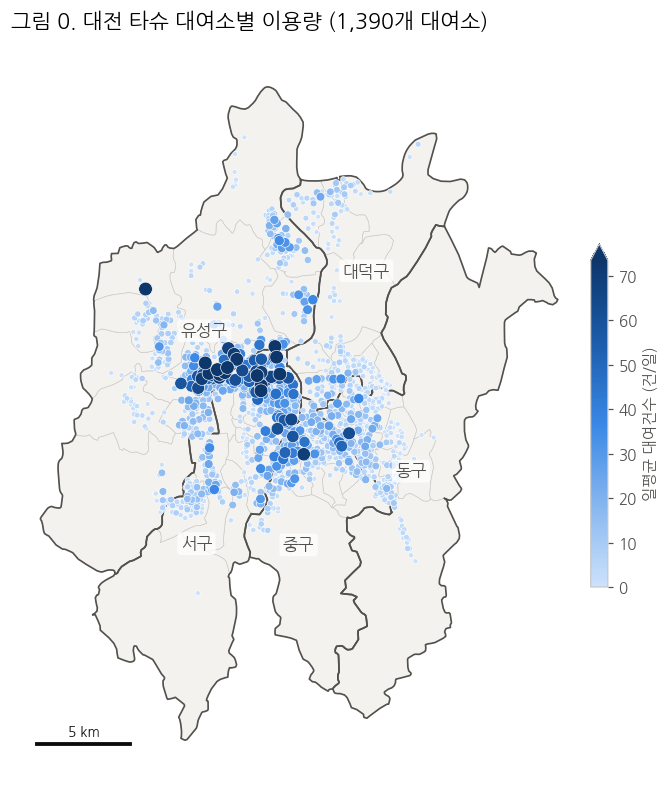

In [ ]:
# 그림 0. 대전 타슈 대여소별 일평균 대여건수 (학습 데이터가 어떤 모습인지)
st = gpd.GeoDataFrame(train, geometry=gpd.points_from_xy(train['lon'], train['lat']),
                      crs=4326).to_crs(CRS_M).sort_values('daily_avg')
fig, ax = plt.subplots(figsize=(8, 9))
draw_base(ax, dong_dj)
mx = st['daily_avg'].quantile(0.99)
sc = ax.scatter(st.geometry.x, st.geometry.y, c=st['daily_avg'], cmap=BLUES,
                vmin=0, vmax=mx, s=10 + 70 * np.clip(st['daily_avg'] / mx, 0, 1),
                edgecolor='white', linewidth=0.4, zorder=5)
cb = fig.colorbar(sc, ax=ax, shrink=0.45, pad=0.01, extend='max')
cb.set_label('일평균 대여건수 (건/일)')
ax.set_title(f'그림 0. 대전 타슈 대여소별 이용량 ({len(st):,}개 대여소)', loc='left')
add_scalebar(ax)
save(fig, '그림0_대전_타슈이용량.png'); plt.show()

## 2. 청주 교통 공백 진단

**생활권 격자:** 가장 가까운 버스정류장이 2km 이내인 격자. 산지·농경지처럼 사람이 거의 다니지 않는 곳을 걸러내는 기준이다(정류장은 사람이 사는 곳을 따라 놓이므로).
**교통 공백 격자:** 생활권이지만 반경 500m 안에 버스정류장이 하나도 없는 격자.

In [ ]:
from sklearn.neighbors import BallTree
EARTH_R = 6_371_000
LIVING_KM = 2.0   # ← 생활권 기준 (가장 가까운 정류장까지 거리)

tree = BallTree(np.radians(bus_cj[['lat', 'lon']].values), metric='haversine')
d, _ = tree.query(np.radians(pred[['lat', 'lon']].values), k=1)
pred['nearest_bus_km'] = d[:, 0] * EARTH_R / 1000
pred['생활권'] = (pred['nearest_bus_km'] <= LIVING_KM) & ~pred.get('거주근무_없음', False)
pred['교통공백'] = pred['생활권'] & (pred['bus_cnt'] == 0)

n_live, n_gap = pred['생활권'].sum(), pred['교통공백'].sum()
print(f'생활권 격자 {n_live:,}개 중 교통 공백 {n_gap:,}개 ({n_gap / n_live:.1%})')

gap_by_dong = (pred[pred['교통공백']].groupby('adm_nm').size()
               .sort_values(ascending=False).rename('공백 격자 수').reset_index())
gap_by_dong['행정동'] = gap_by_dong['adm_nm'].str.split().str[-1]
display(gap_by_dong[['행정동', '공백 격자 수']].head(10))

생활권 격자 3,377개 중 교통 공백 1,649개 (48.8%)


,행정동,공백 격자 수
0,문의면,203
1,미원면,167
2,낭성면,148
3,옥산면,131
4,오창읍,121
5,북이면,115
6,현도면,114
7,내수읍,113
8,가덕면,110
9,남이면,106


저장: /content/drive/MyDrive/데이터/03_결과/그림1_청주_교통공백.png


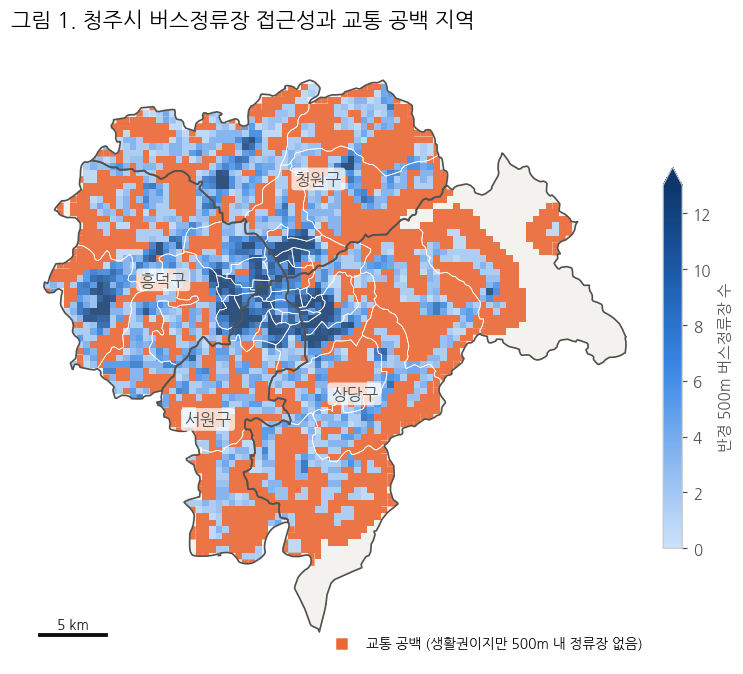

In [ ]:
# 그림 1. 청주 버스 접근성과 교통 공백
gq = gpd.clip(grid_squares(pred), dong_cj)   # 시 경계 밖으로 튀어나온 칸 잘라내기
fig, ax = plt.subplots(figsize=(9, 10))
draw_base(ax, dong_cj)
live = gq[gq['생활권'] & ~gq['교통공백']]
live.plot(ax=ax, column='bus_cnt', cmap=BLUES, vmin=0, vmax=np.nanpercentile(live['bus_cnt'], 95),
          linewidth=0, alpha=0.85, zorder=2, legend=True,
          legend_kwds={'label': '반경 500m 버스정류장 수', 'shrink': 0.45, 'pad': 0.01})
gq[gq['교통공백']].plot(ax=ax, color=ORANGE, linewidth=0, alpha=0.9, zorder=3)
dong_cj.boundary.plot(ax=ax, color='white', linewidth=0.5, zorder=3.5)
ax.scatter([], [], marker='s', color=ORANGE, label='교통 공백 (생활권이지만 500m 내 정류장 없음)')
ax.legend(loc='lower right', frameon=False, fontsize=9)
ax.set_title('그림 1. 청주시 버스정류장 접근성과 교통 공백 지역', loc='left')
add_scalebar(ax)
save(fig, '그림1_청주_교통공백.png'); plt.show()

## 3. 수요 모델 학습·검증

- **목표값:** 대여소 일평균 대여건수의 로그 `log(1 + 건수)` — 소수 대여소에 이용이 몰리는 치우친 분포를 완화
- **예측 모델:** 랜덤포레스트 (변수와 수요의 비선형 관계를 잡아냄)
- **검증:** 학습 80% / 검증 20% 분할 + 5겹 교차검증
- **해석 보조:** 표준화 다중회귀 (각 변수가 수요를 늘리는지 줄이는지 방향 확인)

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.inspection import permutation_importance

X, y_log = train[FEATURES], np.log1p(train['daily_avg'])
X_tr, X_te, y_tr, y_te = train_test_split(X, y_log, test_size=0.2, random_state=42)

rf = RandomForestRegressor(n_estimators=500, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf.fit(X_tr, y_tr)
p_te = rf.predict(X_te)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_r2 = cross_val_score(rf, X, y_log, cv=kf, scoring='r2')
perf = pd.DataFrame({
    '지표': ['R² (검증 20%, 로그)', 'MAE (검증 20%, 건/일)', '5겹 교차검증 R² 평균', '5겹 교차검증 R² 표준편차'],
    '값': [r2_score(y_te, p_te), mean_absolute_error(np.expm1(y_te), np.expm1(p_te)), cv_r2.mean(), cv_r2.std()]
}).round(3)
perf.to_csv(os.path.join(OUT, '표_모델성능.csv'), index=False, encoding='utf-8-sig')
display(perf)

rf.fit(X, y_log)   # 최종 모델은 대전 전체 대여소로 다시 학습

,지표,값
0,"R² (검증 20%, 로그)",0.519
1,"MAE (검증 20%, 건/일)",6.126
2,5겹 교차검증 R² 평균,0.483
3,5겹 교차검증 R² 표준편차,0.046


RandomForestRegressor(min_samples_leaf=5, n_estimators=500, n_jobs=-1,
                      random_state=42)

저장: /content/drive/MyDrive/데이터/03_결과/그림2_변수중요도.png


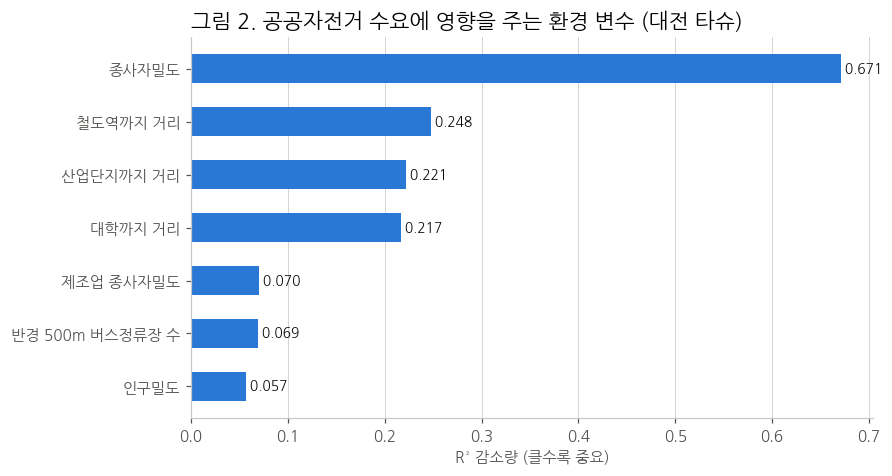

In [ ]:
# 그림 2. 변수 중요도 (순열 중요도: 변수를 섞었을 때 예측력이 얼마나 떨어지는지)
pi = permutation_importance(rf, X_te, y_te, n_repeats=20, random_state=42, n_jobs=-1)
imp = (pd.DataFrame({'변수': [FEAT_KR[f] for f in FEATURES], '중요도': pi.importances_mean})
       .sort_values('중요도'))
imp.sort_values('중요도', ascending=False).to_csv(os.path.join(OUT, '표_변수중요도.csv'),
                                                 index=False, encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp['변수'], imp['중요도'], color=BLUE, height=0.55)
for y_, v in enumerate(imp['중요도']):
    ax.text(v, y_, f' {v:.3f}', va='center', fontsize=9, color=INK)
ax.set_xlabel('R² 감소량 (클수록 중요)')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', color=LINE, linewidth=0.5); ax.set_axisbelow(True)
ax.set_title('그림 2. 공공자전거 수요에 영향을 주는 환경 변수 (대전 타슈)', loc='left')
save(fig, '그림2_변수중요도.png'); plt.show()

In [ ]:
# 해석 보조: 표준화 다중회귀 — 계수의 부호로 '수요를 늘리는/줄이는' 방향을 본다
import statsmodels.api as sm
Xz = (X - X.mean()) / X.std()
ols = sm.OLS(y_log, sm.add_constant(Xz)).fit()
coef = pd.DataFrame({'변수': ['(상수)'] + [FEAT_KR[f] for f in FEATURES],
                     '표준화 계수': ols.params.values, 'p값': ols.pvalues.values}).round(3)
coef['방향'] = np.where(coef['표준화 계수'] > 0, '수요 증가', '수요 감소')
coef.loc[0, '방향'] = ''
coef.to_csv(os.path.join(OUT, '표_회귀계수.csv'), index=False, encoding='utf-8-sig')
print(f'다중회귀 R² = {ols.rsquared:.3f}')
display(coef)

다중회귀 R² = 0.170


,변수,표준화 계수,p값,방향
0,(상수),2.111,0.000,
1,반경 500m 버스정류장 수,0.081,0.003,수요 증가
2,인구밀도,0.120,0.000,수요 증가
3,종사자밀도,0.219,0.000,수요 증가
4,제조업 종사자밀도,-0.055,0.043,수요 감소
5,대학까지 거리,-0.068,0.005,수요 감소
6,철도역까지 거리,0.087,0.001,수요 증가
7,산업단지까지 거리,-0.165,0.000,수요 감소


실제 상위 20% 대여소 중 모델도 상위 20%로 예측한 비율: 57.9%
저장: /content/drive/MyDrive/데이터/03_결과/그림3_예측vs실제.png


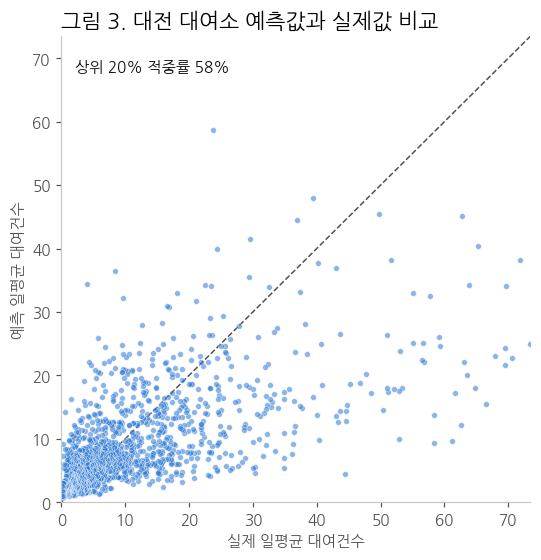

In [ ]:
# 그림 3. 예측 vs 실제 (교차검증 예측값) + 상위 20% 대여소 적중률
oof = np.expm1(cross_val_predict(rf, X, y_log, cv=kf))
actual = train['daily_avg'].values
top_a = actual >= np.quantile(actual, 0.8)
top_p = oof >= np.quantile(oof, 0.8)
hit = (top_a & top_p).sum() / top_a.sum()
print(f'실제 상위 20% 대여소 중 모델도 상위 20%로 예측한 비율: {hit:.1%}')

fig, ax = plt.subplots(figsize=(5.5, 5.5))
lim = np.percentile(np.r_[actual, oof], 99.5)
ax.plot([0, lim], [0, lim], color=INK_2, linewidth=1, linestyle='--', zorder=1)
ax.scatter(actual, oof, s=14, color=BLUE, alpha=0.55, edgecolor='white', linewidth=0.4, zorder=2)
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel('실제 일평균 대여건수'); ax.set_ylabel('예측 일평균 대여건수')
ax.spines[['top', 'right']].set_visible(False)
ax.text(0.03, 0.95, f'상위 20% 적중률 {hit:.0%}', transform=ax.transAxes, fontsize=10, color=INK, va='top')
ax.set_title('그림 3. 대전 대여소 예측값과 실제값 비교', loc='left')
save(fig, '그림3_예측vs실제.png'); plt.show()

## 4. 청주 격자별 잠재 수요 예측
대전에서 학습한 모델을 청주 생활권 격자에 적용한다. 청주 값이 대전 학습 범위를 크게 벗어나는 격자는 예측 신뢰도가 낮으므로 표시해 둔다.

생활권 격자 예측 수요: 평균 3.11건/일, 최대 34.85건/일
외삽 주의 격자: 2,975개 (88.1%)
저장: /content/drive/MyDrive/데이터/03_결과/그림4_청주_잠재수요.png


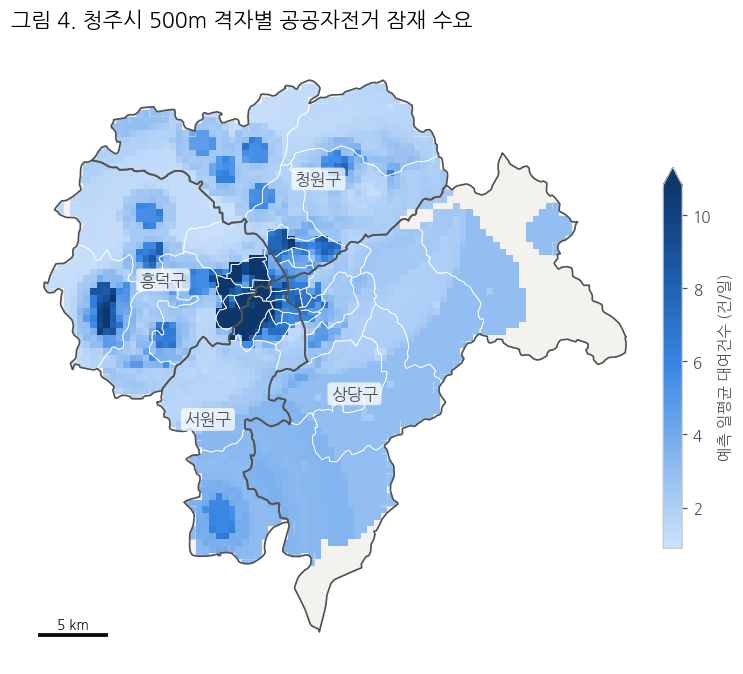

In [ ]:
live_idx = pred['생활권']
pred['예측수요'] = np.nan
pred.loc[live_idx, '예측수요'] = np.expm1(rf.predict(pred.loc[live_idx, FEATURES]))

# 대전 학습 범위(1~99%)를 벗어난 변수가 있는 격자 = 외삽 주의
lo, hi = train[FEATURES].quantile(0.01), train[FEATURES].quantile(0.99)
pred['외삽주의'] = ((pred[FEATURES] < lo) | (pred[FEATURES] > hi)).any(axis=1) & live_idx
print(f'생활권 격자 예측 수요: 평균 {pred["예측수요"].mean():.2f}건/일, 최대 {pred["예측수요"].max():.2f}건/일')
print(f'외삽 주의 격자: {pred["외삽주의"].sum():,}개 ({pred["외삽주의"].sum() / live_idx.sum():.1%})')

gq = gpd.clip(grid_squares(pred), dong_cj)   # 시 경계 밖으로 튀어나온 칸 잘라내기
fig, ax = plt.subplots(figsize=(9, 10))
draw_base(ax, dong_cj)
gq[gq['생활권']].plot(ax=ax, column='예측수요', cmap=BLUES, linewidth=0, zorder=2,
                     vmax=np.nanpercentile(gq['예측수요'], 98), legend=True,
                     legend_kwds={'label': '예측 일평균 대여건수 (건/일)', 'shrink': 0.45, 'pad': 0.01})
dong_cj.boundary.plot(ax=ax, color='white', linewidth=0.5, zorder=3)
ax.set_title('그림 4. 청주시 500m 격자별 공공자전거 잠재 수요', loc='left')
add_scalebar(ax)
save(fig, '그림4_청주_잠재수요.png'); plt.show()

## 5. 우선순위 점수 → 입지 선정

**우선순위 점수 = 예측 수요 × (1 + 버스 취약도)**
- 버스 취약도 = 1 − min(격자 정류장 수 ÷ 대전 대여소 정류장 수 중앙값, 1) → 0(버스 충분) ~ 1(정류장 없음)
- 수요가 같다면 버스가 부족한 곳의 점수가 최대 2배가 된다. 민간·버스가 이미 채운 도심보다 공백 지역을 우선하는 장치다.

**선정 규칙:** 점수가 높은 격자부터 고르되, 이미 고른 곳과 `MIN_DIST_M` 이상 떨어진 곳만 추가한다(대여소가 한곳에 몰리지 않도록). 예산 시나리오 N = 30 · 60 · 100.

**배치 방식 (`OUTER_SHARE`):** 도심은 예측 수요가 외곽보다 훨씬 높아서, 점수만으로 고르면 상위 입지가 도심에 몰린다. 그런데 이 사업의 목적은 버스·민간 공유수단이 채우지 못한 외곽 공백을 메우는 것이므로, N곳 중 일정 비율을 **읍·면 지역에 배정**한다.
- **균형안(기본, `OUTER_SHARE = 0.5`):** N곳의 절반을 읍·면, 절반을 동(도심) 지역에서 각각 점수 순으로 선정
- **효율안(`OUTER_SHARE = None`):** 지역 구분 없이 점수 순으로만 선정 — 비교용으로 함께 저장

In [ ]:
MIN_DIST_M = 1000           # ← 대여소 간 최소 간격(m)
SCENARIOS = [30, 60, 100]  # ← 대여소 수 시나리오
OUTER_SHARE = 0.5          # ← 읍·면 지역 배정 비율 (None이면 효율안)

ref_bus = train['bus_cnt'].median()
pred['버스취약도'] = 1 - np.minimum(pred['bus_cnt'] / ref_bus, 1)
pred['우선순위점수'] = pred['예측수요'] * (1 + pred['버스취약도'])
print(f'기준: 대전 대여소 반경 500m 정류장 수 중앙값 = {ref_bus:.0f}개')

cand = (pred[pred['생활권']].dropna(subset=['우선순위점수'])
        .sort_values('우선순위점수', ascending=False))
cand['행정동'] = cand['adm_nm'].str.split().str[-1]
cand['읍면'] = cand['행정동'].str[-1].isin(['읍', '면'])   # True = 읍·면, False = 동(도심)
is_outer = cand['읍면'].values
cand_m = gpd.GeoDataFrame(cand, geometry=gpd.points_from_xy(cand['lon'], cand['lat']), crs=4326).to_crs(CRS_M)
xy = np.c_[cand_m.geometry.x, cand_m.geometry.y]

def select_sites(n, outer_share=OUTER_SHARE):
    # 점수 순으로 훑으며, 기존 입지와 MIN_DIST_M 이상 떨어진 곳만 고른다.
    # outer_share가 있으면 읍·면 / 동 지역별 할당량을 넘지 않게 고른다.
    if outer_share is None:
        quota = {True: n, False: n}
    else:
        k = int(round(n * outer_share))
        quota = {True: k, False: n - k}
    chosen, count = [], {True: 0, False: 0}
    for rnd in (1, 2):   # 2회차: 한쪽 후보가 모자라면 다른 쪽에서 채움
        for i in range(len(xy)):
            if len(chosen) == n:
                break
            g = bool(is_outer[i])
            if i in chosen or (rnd == 1 and count[g] >= quota[g]):
                continue
            if all(np.hypot(*(xy[i] - xy[j])) >= MIN_DIST_M for j in chosen):
                chosen.append(i); count[g] += 1
    chosen.sort()        # 점수 순서대로 순위 매기기
    out = cand.iloc[chosen].copy()
    out.insert(0, '순위', range(1, len(out) + 1))
    out['구'] = out['adm_nm'].str.split().str[-2].str.replace('청주시', '', regex=False)
    return out

COLS = ['순위', '구', '행정동', 'lat', 'lon', '예측수요', 'bus_cnt', '버스취약도', '우선순위점수', '외삽주의']
sites, sites_eff = {}, {}
for n in SCENARIOS:
    sites[n] = select_sites(n)                       # 균형안 (기본)
    sites_eff[n] = select_sites(n, outer_share=None)  # 효율안 (비교용)
    sites[n][COLS].round(3).to_csv(os.path.join(OUT, f'표_추천입지_N{n}.csv'),
                                   index=False, encoding='utf-8-sig')
    sites_eff[n][COLS].round(3).to_csv(os.path.join(OUT, f'표_추천입지_N{n}_효율안.csv'),
                                       index=False, encoding='utf-8-sig')
display(sites[SCENARIOS[1]][COLS].head(15).round(2))

기준: 대전 대여소 반경 500m 정류장 수 중앙값 = 11개


,순위,구,행정동,lat,lon,예측수요,bus_cnt,버스취약도,우선순위점수,외삽주의
1733,1,흥덕구,복대2동,36.63,127.45,32.25,10,0.09,35.19,False
1981,2,흥덕구,봉명1동,36.64,127.46,34.85,12,0.00,34.85,False
1567,3,흥덕구,가경동,36.62,127.44,25.95,20,0.00,25.95,False
1817,4,서원구,사창동,36.63,127.46,24.74,11,0.00,24.74,False
1317,5,서원구,성화·개신·죽림동,36.60,127.44,14.28,4,0.64,23.36,False
2139,6,흥덕구,봉명2·송정동,36.65,127.44,11.48,0,1.00,22.96,True
1402,7,서원구,성화·개신·죽림동,36.61,127.45,13.66,6,0.45,19.88,False
1571,8,서원구,산남동,36.62,127.46,11.22,4,0.64,18.35,False
2221,9,흥덕구,봉명2·송정동,36.65,127.46,9.89,2,0.82,17.98,True
1976,10,흥덕구,복대1동,36.64,127.43,17.63,14,0.00,17.63,False


저장: /content/drive/MyDrive/데이터/03_결과/그림5_추천입지_N60.png


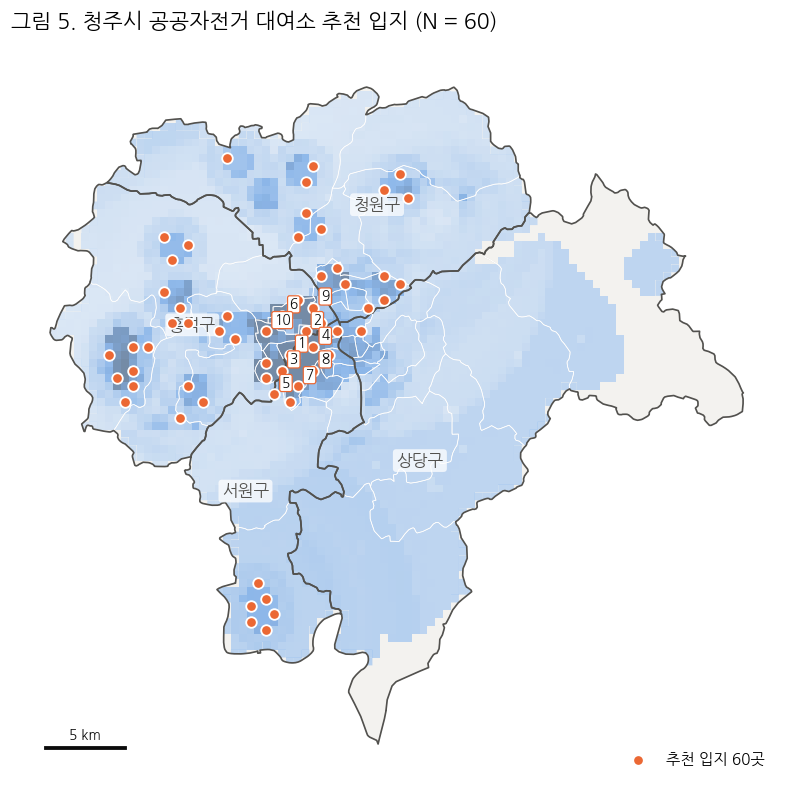

,배치안,시나리오,읍·면 지역 비율,교통 공백 격자 비율,예측 일평균 대여 합계(건)
0,균형안,N = 30,0.500,0.400,359.357
1,균형안,N = 60,0.500,0.417,561.234
2,균형안,N = 100,0.500,0.360,779.606
3,효율안,N = 30,0.267,0.367,371.504
4,효율안,N = 60,0.467,0.383,564.948
5,효율안,N = 100,0.590,0.410,775.996


In [ ]:
# 그림 5. 추천 입지 (가운데 시나리오) — 배경은 잠재 수요, 주황 원은 선정 입지, 상위 10곳은 번호 표시
N_SHOW = SCENARIOS[1]
s = sites[N_SHOW]
s_m = gpd.GeoDataFrame(s, geometry=gpd.points_from_xy(s['lon'], s['lat']), crs=4326).to_crs(CRS_M)

fig, ax = plt.subplots(figsize=(9, 10))
draw_base(ax, dong_cj)
gq[gq['생활권']].plot(ax=ax, column='예측수요', cmap=BLUES, linewidth=0, zorder=2, alpha=0.55,
                     vmax=np.nanpercentile(gq['예측수요'], 98))
dong_cj.boundary.plot(ax=ax, color='white', linewidth=0.5, zorder=3)
ax.scatter(s_m.geometry.x, s_m.geometry.y, s=48, color=ORANGE, edgecolor='white', linewidth=1.2,
           zorder=8, label=f'추천 입지 {N_SHOW}곳')
for _, r in s_m.head(10).iterrows():
    ax.annotate(str(r['순위']), (r.geometry.x, r.geometry.y), xytext=(5, 5), textcoords='offset points',
                fontsize=9, fontweight='bold', color=INK, zorder=9,
                bbox=dict(boxstyle='round,pad=0.15', fc='white', ec=ORANGE, lw=0.8))
ax.legend(loc='lower right', frameon=False, fontsize=10)
ax.set_title(f'그림 5. 청주시 공공자전거 대여소 추천 입지 (N = {N_SHOW})', loc='left')
add_scalebar(ax)
save(fig, f'그림5_추천입지_N{N_SHOW}.png'); plt.show()

# 시나리오별 요약
summary = pd.DataFrame([{
    '배치안': plan, '시나리오': f'N = {n}',
    '읍·면 지역 비율': d[n]['읍면'].mean(),
    '교통 공백 격자 비율': d[n]['교통공백'].mean(),
    '예측 일평균 대여 합계(건)': d[n]['예측수요'].sum(),
} for plan, d in [('균형안', sites), ('효율안', sites_eff)] for n in SCENARIOS]).round(3)
summary.to_csv(os.path.join(OUT, '표_시나리오요약.csv'), index=False, encoding='utf-8-sig')
display(summary)

저장: /content/drive/MyDrive/데이터/03_결과/그림5참고_배치방식비교_N60.png


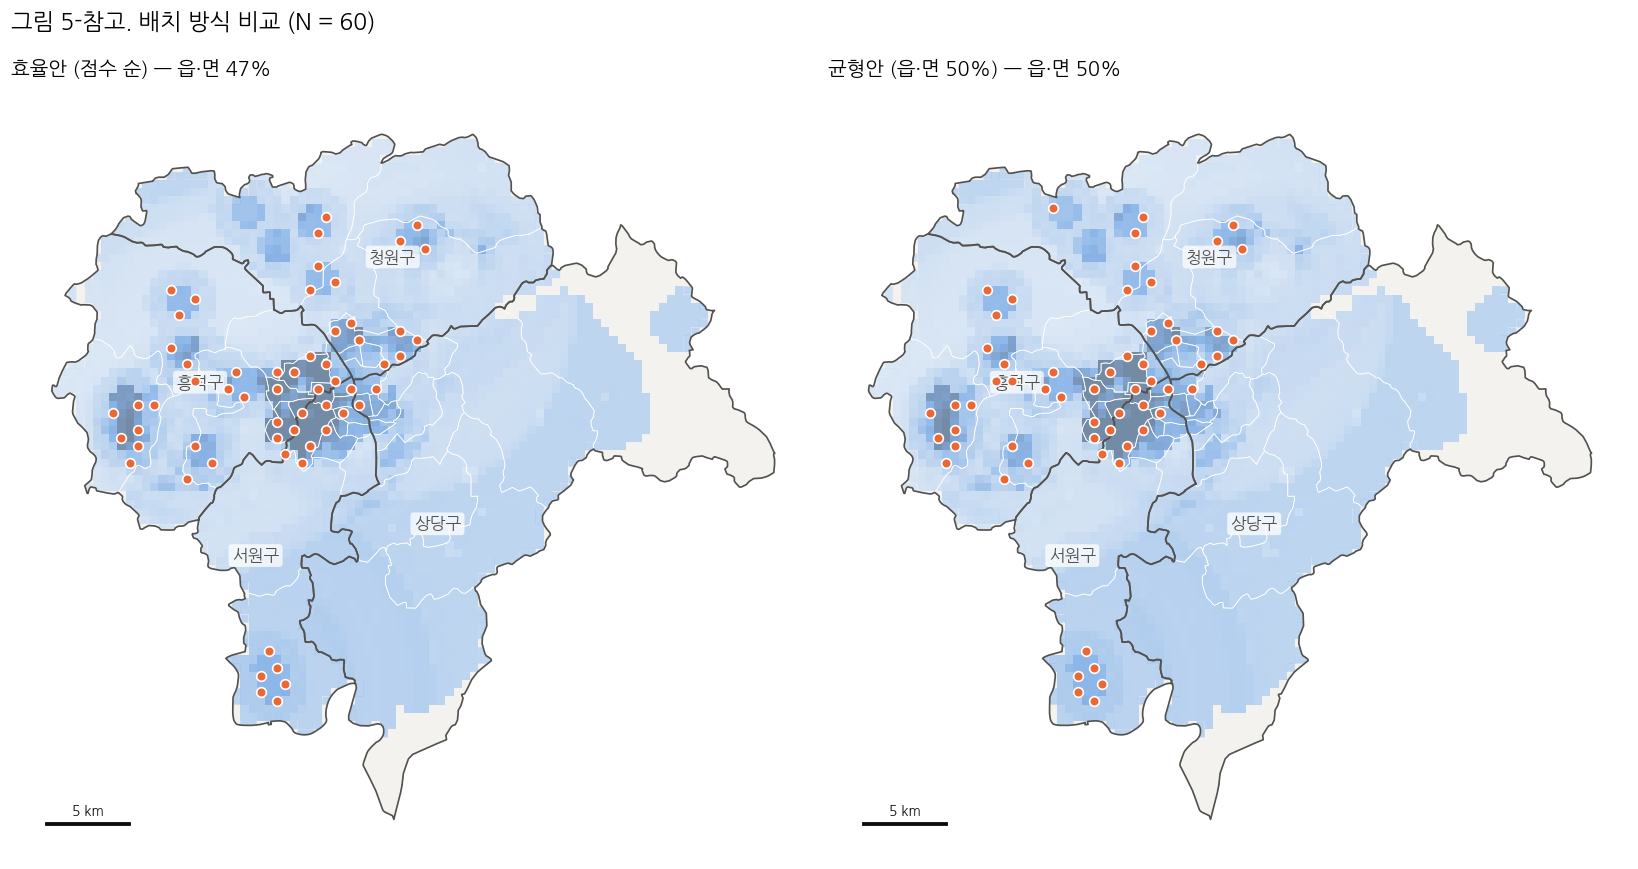

In [ ]:
# 그림 5-참고. 효율안 vs 균형안 비교 (같은 N) — 보고서에서 '왜 균형안인가'를 보여주는 그림
fig, axes = plt.subplots(1, 2, figsize=(15, 8.5))
for ax, (plan, d) in zip(axes, [('효율안 (점수 순)', sites_eff), ('균형안 (읍·면 50%)', sites)]):
    draw_base(ax, dong_cj, gu_labels=True)
    gq[gq['생활권']].plot(ax=ax, column='예측수요', cmap=BLUES, linewidth=0,
                         zorder=2, alpha=0.55, vmax=np.nanpercentile(gq['예측수요'], 98))
    dong_cj.boundary.plot(ax=ax, color='white', linewidth=0.5, zorder=3)
    s_m = gpd.GeoDataFrame(d[N_SHOW], geometry=gpd.points_from_xy(
        d[N_SHOW]['lon'], d[N_SHOW]['lat']), crs=4326).to_crs(CRS_M)
    ax.scatter(s_m.geometry.x, s_m.geometry.y, s=40, color=ORANGE,
               edgecolor='white', linewidth=1.1, zorder=8)
    outer = d[N_SHOW]['읍면'].mean()
    ax.set_title(f'{plan} — 읍·면 {outer:.0%}', loc='left', fontsize=13)
    add_scalebar(ax)
fig.suptitle(f'그림 5-참고. 배치 방식 비교 (N = {N_SHOW})', x=0.01, ha='left',
             fontweight='bold', fontsize=15)
fig.tight_layout()
save(fig, f'그림5참고_배치방식비교_N{N_SHOW}.png'); plt.show()

### 5-1. 추천 입지 상세표 (N = 60)
구·행정동, 가장 가까운 산단·대학·역, 예측 수요, 구글 지도 링크를 정리한다.

In [ ]:
# ▼ 추천 입지 60곳 상세표: 위치(구·행정동), 가까운 주요 시설, 지도 링크
N_TABLE = 60
fac = read_csv_any(os.path.join(PRE, '시설좌표_최종.csv'))
fac = fac[fac['도시'] == '청주'].reset_index(drop=True)
ftree = BallTree(np.radians(fac[['lat', 'lon']].values), metric='haversine')

t = sites[N_TABLE].copy()
d, idx = ftree.query(np.radians(t[['lat', 'lon']].values), k=1)
t['가까운 시설'] = fac.loc[idx[:, 0], '이름'].values
t['시설까지(km)'] = (d[:, 0] * EARTH_R / 1000).round(1)
t['지역 구분'] = np.where(t['행정동'].str[-1].isin(['읍', '면']), '읍·면', '동(도심)')
t['교통 공백'] = np.where(t['교통공백'], '예', '')
t['지도 링크'] = ('https://maps.google.com/?q='
                + t['lat'].round(5).astype(str) + ','
                + t['lon'].round(5).astype(str))

table = t[['순위', '구', '행정동', '지역 구분', '가까운 시설', '시설까지(km)',
           '예측수요', 'bus_cnt', '교통 공백', '지도 링크']].rename(
    columns={'예측수요': '예측 수요(건/일)', 'bus_cnt': '500m 내 정류장'})
table['예측 수요(건/일)'] = table['예측 수요(건/일)'].round(1)
table.to_csv(os.path.join(OUT, f'표_추천입지_N{N_TABLE}_상세.csv'),
             index=False, encoding='utf-8-sig')

print(table.groupby(['구', '지역 구분']).size().unstack(fill_value=0))
pd.set_option('display.max_rows', 100)
display(table)

지역 구분  동(도심)  읍·면
구                
상당구        1    0
서원구        7    6
청원구        8    8
흥덕구       14   16


,순위,구,행정동,지역 구분,가까운 시설,시설까지(km),예측 수요(건/일),500m 내 정류장,교통 공백,지도 링크
1733,1,흥덕구,복대2동,동(도심),충북대학교,0.6,32.3,10,,"https://maps.google.com/?q=36.62623,127.4473"
1981,2,흥덕구,봉명1동,동(도심),충북대학교,1.4,34.8,12,,"https://maps.google.com/?q=36.63976,127.45848"
1567,3,흥덕구,가경동,동(도심),충북대학교,1.6,26.0,20,,"https://maps.google.com/?q=36.61721,127.44172"
1817,4,서원구,사창동,동(도심),충북대학교,1.0,24.7,11,,"https://maps.google.com/?q=36.63074,127.46408"
1317,5,서원구,성화·개신·죽림동,동(도심),충북대학교,3.1,14.3,4,,"https://maps.google.com/?q=36.60369,127.43614"
2139,6,흥덕구,봉명2·송정동,동(도심),청주일반산업단지,1.3,11.5,0,예,"https://maps.google.com/?q=36.64876,127.4417"
1402,7,서원구,성화·개신·죽림동,동(도심),충북대학교,2.2,13.7,6,,"https://maps.google.com/?q=36.6082,127.45291"
1571,8,서원구,산남동,동(도심),충북대학교,1.5,11.2,4,,"https://maps.google.com/?q=36.61722,127.46409"
2221,9,흥덕구,봉명2·송정동,동(도심),충북대학교,2.9,9.9,2,,"https://maps.google.com/?q=36.65328,127.46407"
1976,10,흥덕구,복대1동,동(도심),청주일반산업단지,0.5,17.6,14,,"https://maps.google.com/?q=36.63974,127.43052"


### 5-2. 대여소 수(N) 적정 규모 확인
- **추가 대여소의 예측 수요:** 대전 타슈 하위 25% 대여소 수준 아래로 떨어지기 전까지는 설치할 가치가 있다고 본다.
- **교통 공백 커버율:** 교통 공백 격자 중 대여소 1km 안에 들어오는 비율. 형평성 지표.

기준선(대전 하위 25% 대여소 수요): 3.04건/일
→ 이 기준 이상 수요가 예상되는 입지 수: 182곳


,N,누적 예측수요(건/일),추가 10곳 평균 예측수요,교통공백 격자 1km 커버율
2,30,371.504,7.357,0.045
5,60,564.948,6.017,0.100
9,100,775.996,4.415,0.161
14,150,960.126,3.672,0.280
19,200,1120.819,2.931,0.389
29,300,1376.564,1.395,0.557


저장: /content/drive/MyDrive/데이터/03_결과/그림6_대여소수별_효과.png


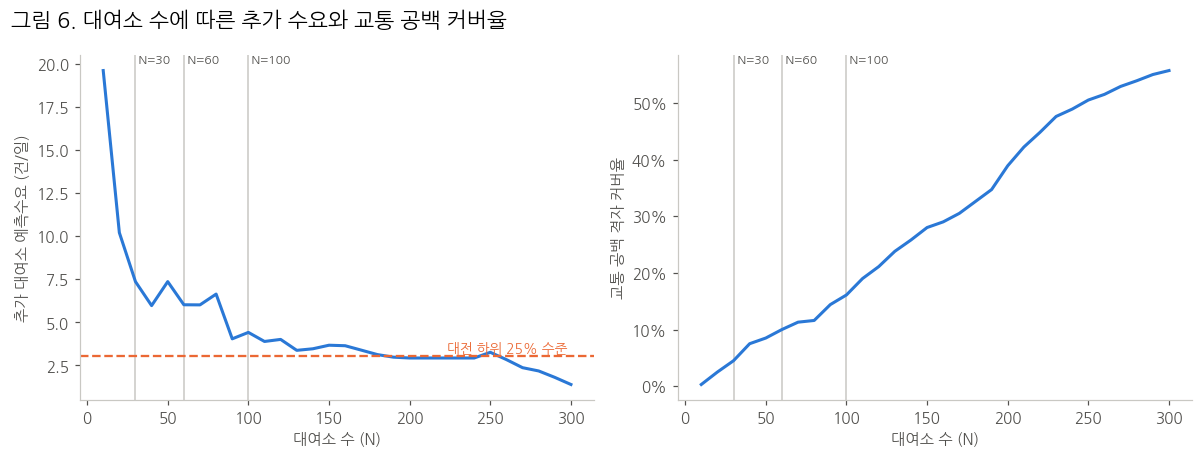

In [ ]:
# ▼ 대여소 수(N)를 늘릴 때 얻는 효과 비교 → 적정 규모 판단
N_MAX = 300
seq = select_sites(N_MAX)   # 점수 순서대로 고른 목록 (앞 N개 = N 시나리오)
Ns = np.arange(10, len(seq) + 1, 10)

# ① 기준선: 대전 타슈 대여소 중 하위 25%의 일평균 대여건수
#    → 이보다 낮으면 대전에서도 '이용이 적은 대여소' 수준
floor = train['daily_avg'].quantile(0.25)
n_floor = int((seq['예측수요'] >= floor).sum())  # 기준 이상인 입지 수

# ② 교통 공백 격자 중 대여소 1km 안에 들어오는 비율 (형평성 지표)
gap = pred[pred['교통공백']]
gtree = BallTree(np.radians(gap[['lat', 'lon']].values), metric='haversine')
def gap_cover(n):
    pts = np.radians(seq.head(n)[['lat', 'lon']].values)
    hit = gtree.query_radius(pts, r=1000 / EARTH_R)
    return len(set(np.concatenate(hit))) / len(gap) if len(gap) else np.nan

curve = pd.DataFrame({
    'N': Ns,
    '누적 예측수요(건/일)': [seq.head(n)['예측수요'].sum() for n in Ns],
    # 점수 순으로 고르므로 수요가 들쭉날쭉 → 직전 10곳 평균으로 본다
    '추가 10곳 평균 예측수요':
        [seq.iloc[n - 10:n]['예측수요'].mean() for n in Ns],
    '교통공백 격자 1km 커버율': [gap_cover(n) for n in Ns],
}).round(3)
curve.to_csv(os.path.join(OUT, '표_대여소수별_효과.csv'),
             index=False, encoding='utf-8-sig')

print(f'기준선(대전 하위 25% 대여소 수요): {floor:.2f}건/일')
print(f'→ 이 기준 이상 수요가 예상되는 입지 수: {n_floor}곳')
display(curve[curve['N'].isin([30, 60, 100, 150, 200, 300])])

# 그림 6. 대여소 수에 따른 효과 (두 지표를 나란히 — 축 하나씩)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
panels = [(axes[0], '추가 10곳 평균 예측수요', '추가 대여소 예측수요 (건/일)'),
          (axes[1], '교통공백 격자 1km 커버율', '교통 공백 격자 커버율')]
for ax, col, ylab in panels:
    ax.plot(curve['N'], curve[col], color=BLUE, linewidth=2)
    for n in [30, 60, 100]:
        ax.axvline(n, color=LINE, linewidth=1, zorder=0)
        ax.text(n, ax.get_ylim()[1], f' N={n}', fontsize=8, color=INK_2, va='top')
    ax.set_xlabel('대여소 수 (N)'); ax.set_ylabel(ylab)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].axhline(floor, color=ORANGE, linewidth=1.5, linestyle='--')
axes[0].text(Ns[-1], floor, '대전 하위 25% 수준 ', color=ORANGE, fontsize=9,
             ha='right', va='bottom')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
TITLE6 = '그림 6. 대여소 수에 따른 추가 수요와 교통 공백 커버율'
fig.suptitle(TITLE6, x=0.01, ha='left', fontweight='bold', fontsize=14)
fig.tight_layout()
save(fig, '그림6_대여소수별_효과.png'); plt.show()

## 6. 후보 지역 가설 확인
분석 전에 세운 후보 지역(산단·신규 주거·교통 결절점)이 데이터로 고른 입지에 실제로 나타나는지 확인한다. 나타나면 결과의 타당성 근거가 되고, 나타나지 않으면 그 이유를 보고서에서 해석한다.

In [ ]:
HYPOTHESIS = {'오창읍': '오창과학산단', '오송읍': '오송생명과학단지·오송역', '강서2동': '청주테크노폴리스',
              '옥산면': '옥산산단', '강내면': '강내산단·한국교원대', '봉명2·송정동': '청주일반산단',
              '현도면': '현도산단', '내수읍': '내수농공단지·청주공항'}
rows = []
for dong_nm, desc in HYPOTHESIS.items():
    row = {'행정동': dong_nm, '후보 근거': desc}
    for n in SCENARIOS:
        row[f'N={n} 선정 수'] = int((sites[n]['행정동'] == dong_nm).sum())
    rows.append(row)
hyp = pd.DataFrame(rows)
hyp['판정'] = np.where(hyp[f'N={SCENARIOS[-1]} 선정 수'] > 0, '나타남', '나타나지 않음 → 이유 해석')
hyp.to_csv(os.path.join(OUT, '표_후보지역확인.csv'), index=False, encoding='utf-8-sig')
display(hyp)

,행정동,후보 근거,N=30 선정 수,N=60 선정 수,N=100 선정 수,판정
0,오창읍,오창과학산단,1,5,11,나타남
1,오송읍,오송생명과학단지·오송역,2,7,10,나타남
2,강서2동,청주테크노폴리스,0,0,1,나타남
3,옥산면,옥산산단,5,6,7,나타남
4,강내면,강내산단·한국교원대,1,3,4,나타남
5,봉명2·송정동,청주일반산단,3,3,3,나타남
6,현도면,현도산단,4,6,12,나타남
7,내수읍,내수농공단지·청주공항,2,3,3,나타남


## 7. 효과 추정 (이용량·탄소 절감)

**연간 이용 = 선정 입지 예측 일평균 합계 × 365**
**탄소 절감 = 연간 이용 × 평균 이용거리(km) × 자가용 대체 비율 × 승용차 배출계수(kg/km)**

연간 이용과 평균 이용거리는 실제 데이터로 계산한 값이다. 자가용 대체 비율과 승용차 배출계수는 지역 단위 실측 자료가 없어 **가정값**을 적용했으며, 결과는 단일 값이 아닌 **범위(낮음·중간·높음)**로 제시한다.

In [ ]:
# 이용 건수로 가중한 타슈 평균 이용거리(km) — 실제 데이터
w = train['daily_avg']
AVG_KM = (train['avg_dist'] * w).sum() / w.sum()

# 가정값 (지역 실측 자료 없음 → 범위로 제시)
SUBST = {'낮음': 0.10, '중간': 0.20, '높음': 0.30}   # 자가용 대체 비율
EF_KG_PER_KM = 0.2                                  # 승용차 CO₂ 배출계수(kg/km)
print(f'타슈 평균 이용거리(이용 건수 가중): {AVG_KM:.2f} km')

rows = []
for n in SCENARIOS:
    annual = sites[n]['예측수요'].sum() * 365
    row = {'시나리오': f'N = {n}',
           '연간 예상 이용(건)': round(annual),
           '연간 이동거리(km)': round(annual * AVG_KM)}
    for k, v in SUBST.items():
        t = annual * AVG_KM * v * EF_KG_PER_KM / 1000
        row[f'CO₂ 절감 t ({k}, 가정)'] = round(t, 1)
    rows.append(row)
effect = pd.DataFrame(rows)
effect.to_csv(os.path.join(OUT, '표_효과추정.csv'), index=False, encoding='utf-8-sig')
display(effect)